# Figure 2: the same ligand as a SMILES string and as a CCD code

Oxadiazon (CCD `S6Z`) from PXR structure 7AXE. The SMILES input gets generated atom labels (C1, C2, O1 ...); the CCD input keeps the names deposited with the PDB entry.

Inputs: `structures/S6Z_ccd.cif` (the chemical-component entry from the wwPDB) and `structures/7AXE.cif`. Needs RDKit and biotite.

In [1]:
import io
from pathlib import Path

import biotite.structure.io.pdbx as pdbx
import matplotlib as mpl
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit.Chem.Draw import rdMolDraw2D

ROOT = Path.cwd().parent
CODE, PDBID, NAME = "S6Z", "7AXE", "oxadiazon"
SMILES = "CC(C)Oc1cc(N2N=C(OC2=O)C(C)(C)C)c(Cl)cc1Cl"   # canonical SMILES from the CCD entry

## Gate: the ligand really is in 7AXE

In [2]:
arr = pdbx.get_structure(pdbx.CIFFile.read(ROOT / "structures" / f"{PDBID}.cif"), model=1)
assert CODE in set(arr.res_name), f"{CODE} not found in {PDBID}"
print(CODE, "found in", PDBID)

S6Z found in 7AXE


## The CCD graph (deposited names) and the SMILES graph, mapped atom to atom
Hard gates: same molecule, same atom count, full match.

In [3]:
blk = pdbx.CIFFile.read(ROOT / "structures" / f"{CODE}_ccd.cif").block
at, bd = blk["chem_comp_atom"], blk["chem_comp_bond"]
names, elems = list(at["atom_id"].as_array()), list(at["type_symbol"].as_array())
keep = [i for i, e in enumerate(elems) if e != "H"]            # heavy atoms only
rw, idx = Chem.RWMol(), {}
for i in keep:
    idx[names[i]] = rw.AddAtom(Chem.Atom(elems[i].capitalize()))
order = {"SING": Chem.BondType.SINGLE, "DOUB": Chem.BondType.DOUBLE, "TRIP": Chem.BondType.TRIPLE}
for a1, a2, o in zip(bd["atom_id_1"].as_array(), bd["atom_id_2"].as_array(), bd["value_order"].as_array()):
    if a1 in idx and a2 in idx:
        rw.AddBond(idx[a1], idx[a2], order[o])
ccd = rw.GetMol()
Chem.SanitizeMol(ccd)
deposited = {v: k for k, v in idx.items()}                      # CCD atom index -> deposited name

smi = Chem.MolFromSmiles(SMILES)
assert Chem.MolToSmiles(ccd) == Chem.MolToSmiles(Chem.MolFromSmiles(Chem.MolToSmiles(smi, isomericSmiles=False))), "CCD graph != SMILES graph"
NH = len(keep)
assert smi.GetNumAtoms() == ccd.GetNumAtoms() == NH
match = smi.GetSubstructMatch(ccd)                              # CCD atom i -> SMILES atom match[i]
assert len(match) == NH and len(set(match)) == NH

# generated names: element + running count in SMILES atom order (what a model assigns a SMILES input)
count, gen_smi = {}, {}
for a in smi.GetAtoms():
    s = a.GetSymbol()
    count[s] = count.get(s, 0) + 1
    gen_smi[a.GetIdx()] = f"{s.upper()}{count[s]}"
generated = {i: gen_smi[match[i]] for i in range(NH)}
print("deposited:", [deposited[i] for i in range(NH)])
print("generated:", [generated[i] for i in range(NH)])

deposited: [np.str_('CAA'), np.str_('CAB'), np.str_('CAC'), np.str_('CAD'), np.str_('CAE'), np.str_('CAJ'), np.str_('CAK'), np.str_('CAN'), np.str_('CAO'), np.str_('CAP'), np.str_('CAQ'), np.str_('CAR'), np.str_('CAS'), np.str_('CAU'), np.str_('CAV'), np.str_('NAL'), np.str_('NAT'), np.str_('OAH'), np.str_('OAI'), np.str_('OAM'), np.str_('CL1'), np.str_('CL2')]
generated: ['C1', 'C3', 'C10', 'C11', 'C12', 'C14', 'C5', 'C2', 'C15', 'C13', 'C4', 'C6', 'C7', 'C8', 'C9', 'N2', 'N1', 'O3', 'O1', 'O2', 'CL2', 'CL1']


## Figure

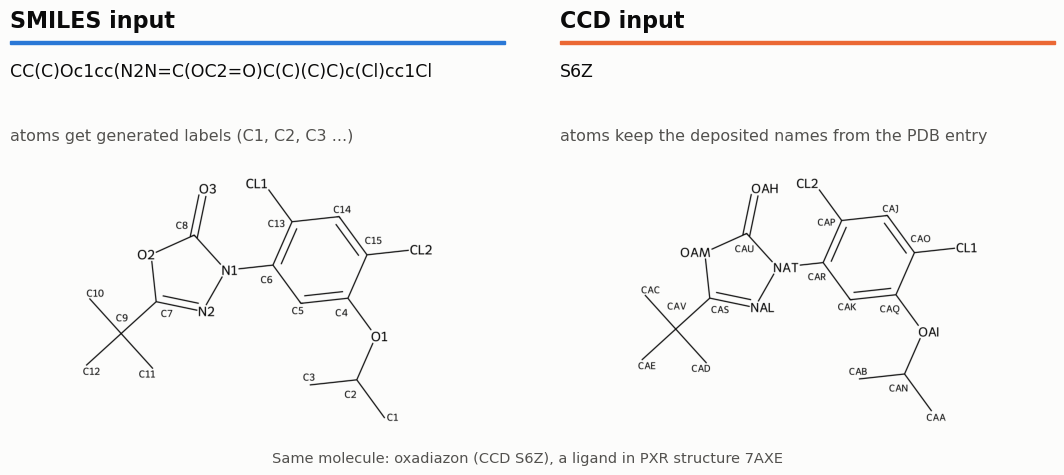

In [4]:
AllChem.Compute2DCoords(smi)
to_ccd = {v: k for k, v in enumerate(match)}                    # SMILES atom index -> CCD atom index


def draw(labels):
    mol = Chem.Mol(smi)
    d = rdMolDraw2D.MolDraw2DCairo(1000, 520)
    o = d.drawOptions()
    for a in mol.GetAtoms():
        if a.GetSymbol() == "C":
            a.SetProp("atomNote", labels[to_ccd[a.GetIdx()]])           # carbons: small label beside the vertex
        else:
            o.atomLabels[a.GetIdx()] = labels[to_ccd[a.GetIdx()]]       # heteroatoms: the name replaces the symbol
    o.baseFontSize, o.annotationFontScale, o.bondLineWidth, o.padding = 0.42, 0.75, 2.4, 0.03
    o.setBackgroundColour((1, 1, 1, 0))
    o.useBWAtomPalette()
    d.DrawMolecule(mol)
    d.FinishDrawing()
    return mpimg.imread(io.BytesIO(d.GetDrawingText()), format="png")


INK, INK2 = "#0b0b0b", "#52514e"
mpl.rcParams.update({"font.size": 11, "figure.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb"})
fig = plt.figure(figsize=(11, 4.7))
panels = [(0.03, "#2a78d6", "SMILES input", SMILES, "atoms get generated labels (C1, C2, C3 ...)", draw(generated)),
          (0.53, "#eb6834", "CCD input", CODE, "atoms keep the deposited names from the PDB entry", draw(deposited))]
for x0, col, title, text, sub, img in panels:
    ax = fig.add_axes([x0, 0.07, 0.45, 0.58])
    ax.imshow(img)
    ax.axis("off")
    fig.patches.append(plt.Rectangle((x0, 0.905), 0.45, 0.006, transform=fig.transFigure, color=col))
    fig.text(x0, 0.94, title, fontsize=16, fontweight="bold", color=INK)
    fig.text(x0, 0.865, text, fontsize=12.5, color=INK, va="top")
    fig.text(x0, 0.70, sub, fontsize=11.5, color=INK2)
fig.text(0.5, 0.015, f"Same molecule: {NAME} (CCD {CODE}), a ligand in PXR structure {PDBID}", ha="center", fontsize=10.5, color=INK2)
fig.savefig(ROOT / "figures" / "fig2_input_schematic.png", dpi=200)
plt.show()